In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
pd.set_option('display.max_columns', None)

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("vivek468/superstore-dataset-final")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'superstore-dataset-final' dataset.
Path to dataset files: /kaggle/input/superstore-dataset-final


In [ ]:
df = pd.read_csv('/kaggle/input/superstore-dataset-final/Sample - Superstore.csv', encoding='latin1')

In [ ]:
df.shape

(9994, 21)

In [ ]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [ ]:
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

In [ ]:
df.nunique()

,0
Row ID,9994
Order ID,5009
Order Date,1237
Ship Date,1334
Ship Mode,4
Customer ID,793
Customer Name,793
Segment,3
Country,1
City,531


In [ ]:
df.drop(columns=['Row ID', 'Postal Code'], inplace = True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order ID       9994 non-null   object        
 1   Order Date     9994 non-null   datetime64[ns]
 2   Ship Date      9994 non-null   datetime64[ns]
 3   Ship Mode      9994 non-null   object        
 4   Customer ID    9994 non-null   object        
 5   Customer Name  9994 non-null   object        
 6   Segment        9994 non-null   object        
 7   Country        9994 non-null   object        
 8   City           9994 non-null   object        
 9   State          9994 non-null   object        
 10  Region         9994 non-null   object        
 11  Product ID     9994 non-null   object        
 12  Category       9994 non-null   object        
 13  Sub-Category   9994 non-null   object        
 14  Product Name   9994 non-null   object        
 15  Sales          9994 n

In [ ]:
(df.duplicated().sum() / len(df)) * 100

np.float64(0.010006003602161296)

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0
State,0


## Data Understanding

In [ ]:
df.describe()

,Order Date,Ship Date,Sales,Quantity,Discount,Profit
count,9993,9993,9993.000000,9993.000000,9993.000000,9993.000000
mean,2016-04-30 01:53:33.089162240,2016-05-04 00:53:19.039327488,229.852846,3.789753,0.156188,28.660971
min,2014-01-03 00:00:00,2014-01-07 00:00:00,0.444000,1.000000,0.000000,-6599.978000
25%,2015-05-23 00:00:00,2015-05-27 00:00:00,17.280000,2.000000,0.000000,1.731000
50%,2016-06-26 00:00:00,2016-06-29 00:00:00,54.480000,3.000000,0.200000,8.671000
75%,2017-05-14 00:00:00,2017-05-18 00:00:00,209.940000,5.000000,0.200000,29.364000
max,2017-12-30 00:00:00,2018-01-05 00:00:00,22638.480000,14.000000,0.800000,8399.976000
std,NaN,NaN,623.276074,2.225149,0.206457,234.271476


In [ ]:
num_col = ['Sales', 'Quantity', 'Discount', 'Profit', 'Order Date', 'Ship Date']
cat_col = [x for x in df.columns.tolist() if x not in num_col]

In [ ]:
df[cat_col].describe()

,Order ID,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Region,Product ID,Category,Sub-Category,Product Name
count,9993,9993,9993,9993,9993,9993,9993,9993,9993,9993,9993,9993,9993
unique,5009,4,793,793,3,1,531,49,4,1862,3,17,1850
top,CA-2017-100111,Standard Class,WB-21850,William Brown,Consumer,United States,New York City,California,West,OFF-PA-10001970,Office Supplies,Binders,Staple envelope
freq,14,5967,37,37,5191,9993,915,2001,3203,19,6026,1523,48


In [ ]:
df.describe(include='object')

,Order ID,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Region,Product ID,Category,Sub-Category,Product Name
count,9993,9993,9993,9993,9993,9993,9993,9993,9993,9993,9993,9993,9993
unique,5009,4,793,793,3,1,531,49,4,1862,3,17,1850
top,CA-2017-100111,Standard Class,WB-21850,William Brown,Consumer,United States,New York City,California,West,OFF-PA-10001970,Office Supplies,Binders,Staple envelope
freq,14,5967,37,37,5191,9993,915,2001,3203,19,6026,1523,48


(0.0, 1000.0)

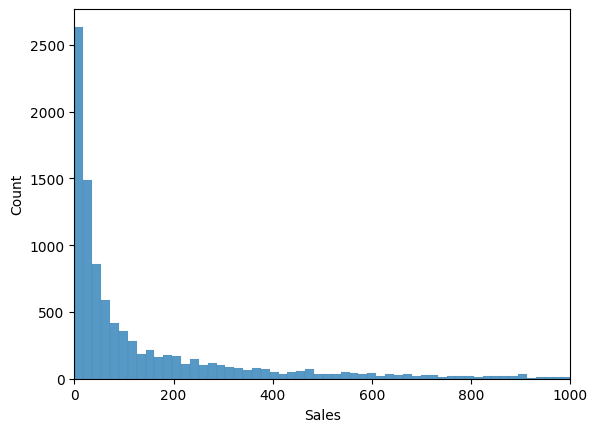

In [ ]:
sns.histplot(data=df, x='Sales', fill=True)
plt.xlim(0, 1000)

<Axes: ylabel='Order ID'>

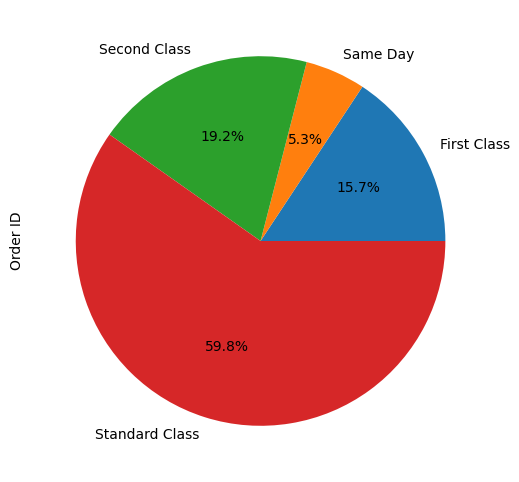

In [ ]:
df.groupby('Ship Mode')['Order ID'].nunique().plot(kind='pie', autopct='%1.1f%%', figsize=(6,6))

<Axes: ylabel='Order ID'>

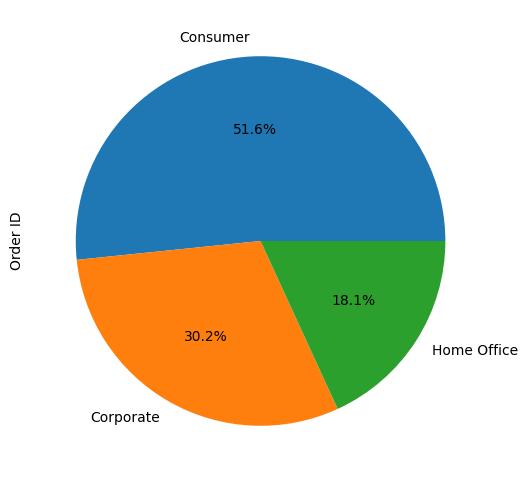

In [ ]:
df.groupby('Segment')['Order ID'].nunique().plot(kind='pie', autopct='%1.1f%%', figsize=(6,6))

In [ ]:
df.nunique()

,0
Order ID,5009
Order Date,1237
Ship Date,1334
Ship Mode,4
Customer ID,793
Customer Name,793
Segment,3
Country,1
City,531
State,49


## EDA

### Univariate Analysis

<Axes: ylabel='Customer ID'>

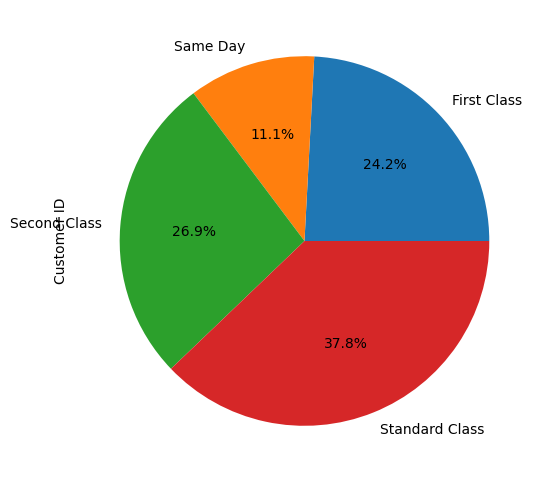

In [ ]:
df.groupby('Ship Mode')['Customer ID'].nunique().plot(kind='pie', autopct='%1.1f%%', figsize=(6,6))

In [ ]:
df['diff_date'] = (df['Ship Date'] - df['Order Date']).dt.days # Feature Engineering

<Axes: xlabel='diff_date', ylabel='Density'>

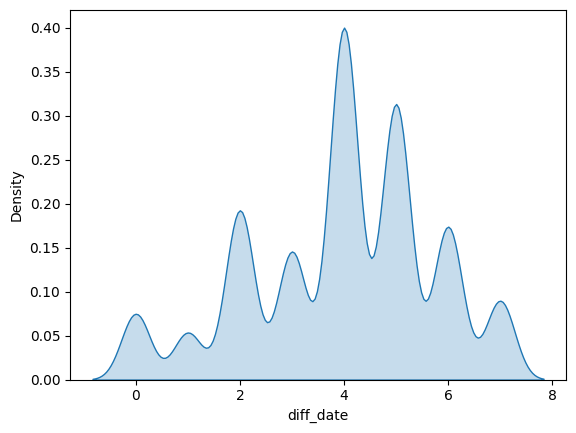

In [ ]:
sns.kdeplot(data=df, x='diff_date', fill=True)

### Bivariate Analysis

<Axes: xlabel='diff_date', ylabel='Density'>

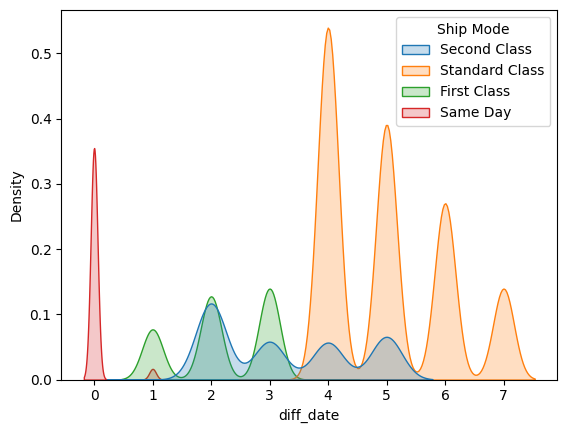

In [ ]:
sns.kdeplot(data=df, x='diff_date', fill=True, hue='Ship Mode')

In [ ]:
df['ship_mode_encode'] = df['Ship Mode'].map({
    'Second Class': 3,
    'Standard Class': 4,
    'First Class': 2,
    'Same Day': 1})

In [ ]:
df[['ship_mode_encode', 'diff_date']].corr()

,ship_mode_encode,diff_date
ship_mode_encode,1.000000,0.819092
diff_date,0.819092,1.000000


In [ ]:
df['price_per_product'] = df['Sales'] / df['Quantity']
df['profit_per_product'] = df['Profit'] / df['Quantity']
df['net_price'] = df['price_per_product'] - df['profit_per_product']

/tmp/ipykernel_3703/1661513359.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=data, y='Product Name', x='Profit', ax = ax, palette='tab10')


<Axes: xlabel='Profit', ylabel='Product Name'>

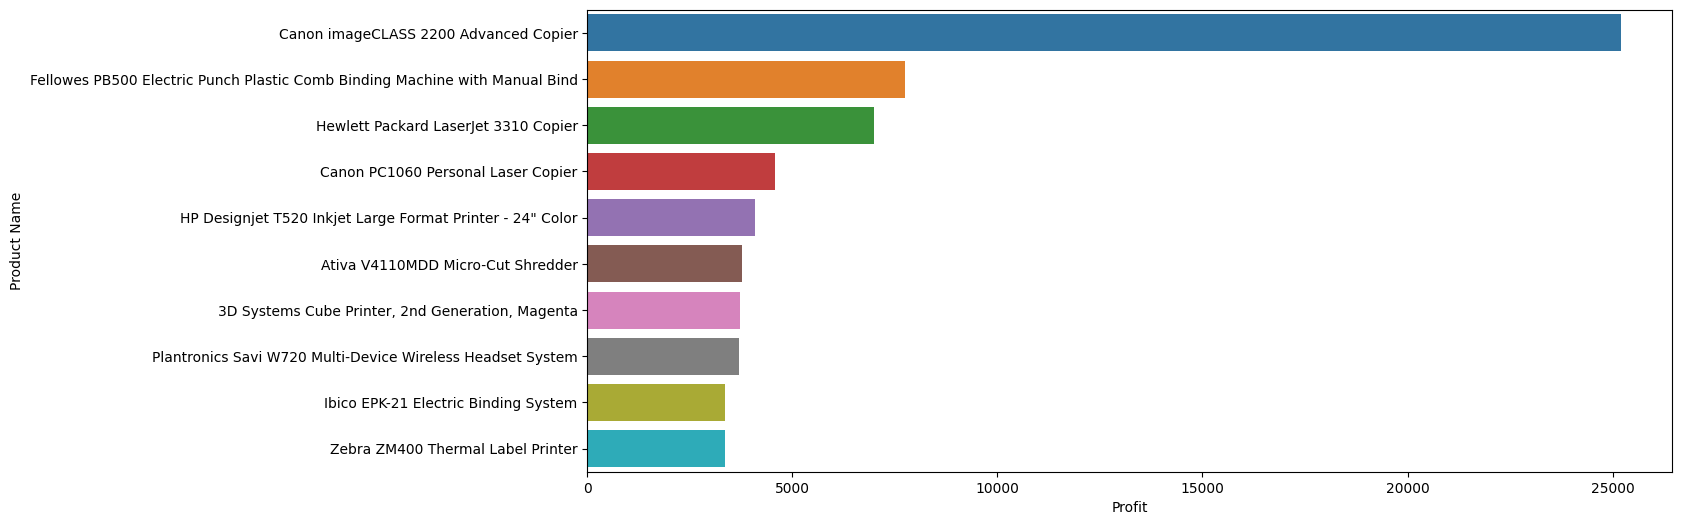

In [ ]:
data = df.groupby('Product Name')['Profit'].sum().reset_index().sort_values(by='Profit', ascending=False).head(10)
fig, ax = plt.subplots(figsize=(14,6))
sns.barplot(data=data, y='Product Name', x='Profit', ax = ax, palette='tab10')

/tmp/ipykernel_3703/3925490252.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=data, y='Product Name', x='profit_per_product', ax = ax, palette='tab10')


<Axes: xlabel='profit_per_product', ylabel='Product Name'>

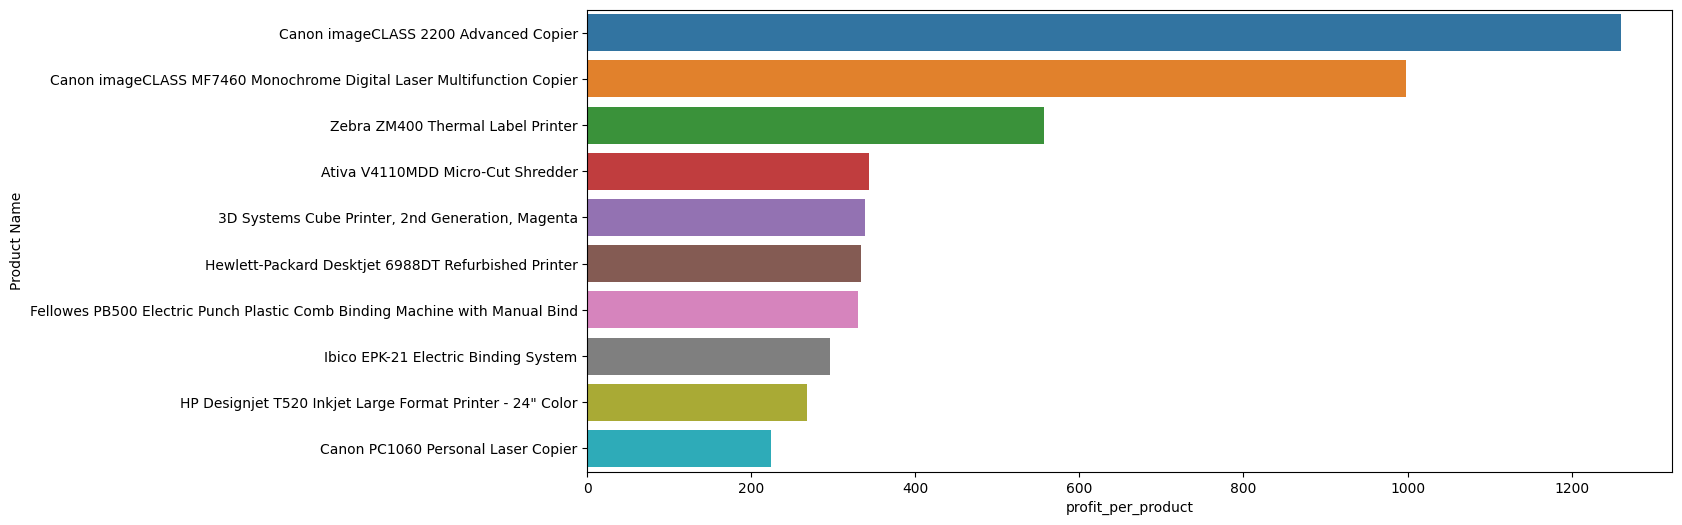

In [ ]:
data = df.groupby('Product Name')['profit_per_product'].mean().reset_index().sort_values(by='profit_per_product', ascending=False).head(10)
fig, ax = plt.subplots(figsize=(14,6))
sns.barplot(data=data, y='Product Name', x='profit_per_product', ax = ax, palette='tab10')

Text(0.5, 1.0, 'Quantity by Category')

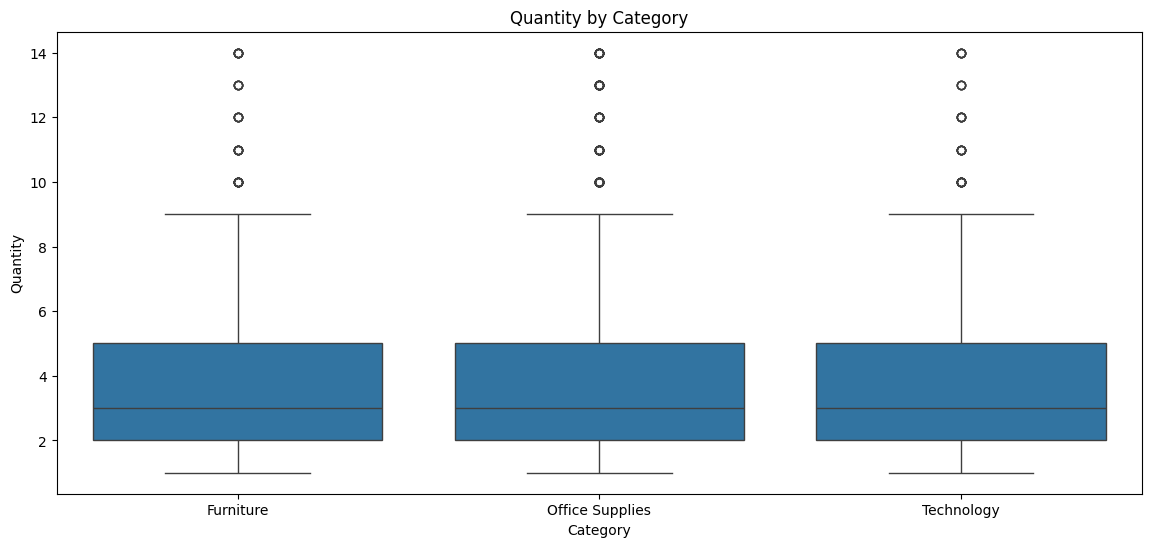

In [ ]:
fig, ax = plt.subplots(figsize=(14,6))
sns.boxplot(data=df, x='Category', y='Quantity', ax=ax)
plt.title('Quantity by Category')

In [ ]:
iqr = df['Sales'].quantile(0.75) - df['Sales'].quantile(0.25)
upper = df['Sales'].quantile(0.75) + 1.5 * iqr
lower = df['Sales'].quantile(0.25) - 1.5 * iqr

In [ ]:
# df[(df['Category'] == 'Technology') & (df['Sales'] > upper)].sort_values(by='Sales', ascending=False)

### Multivariate Analysis

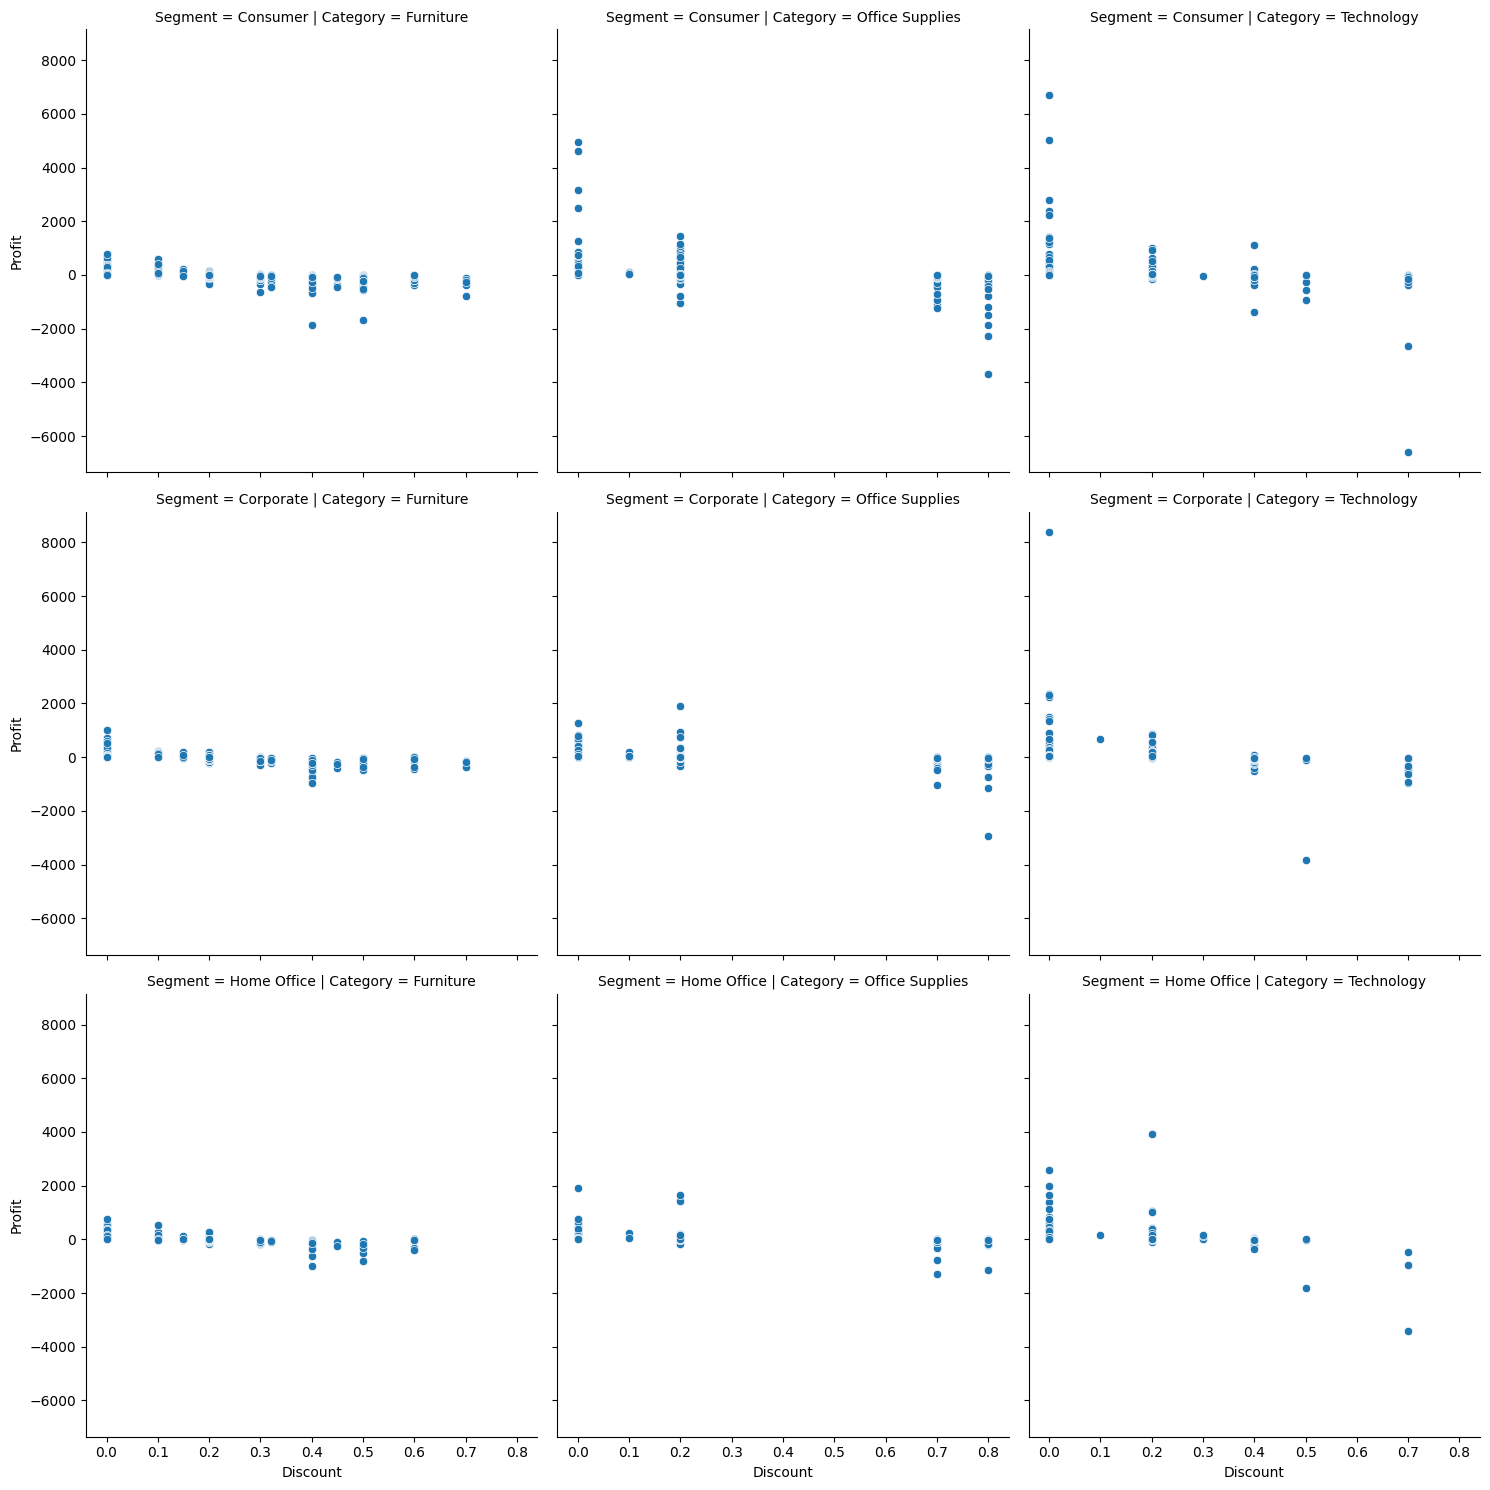

In [ ]:
sns.relplot(data=df, x='Discount', y='Profit', row='Segment', col='Category')

In [ ]:
num_col = df.select_dtypes(include='number').columns.tolist()
excl = ['Row ID', 'Postal Code']
col = [x for x in num_col if x not in excl]

In [ ]:
data_corr = df[col].corr()

<Axes: >

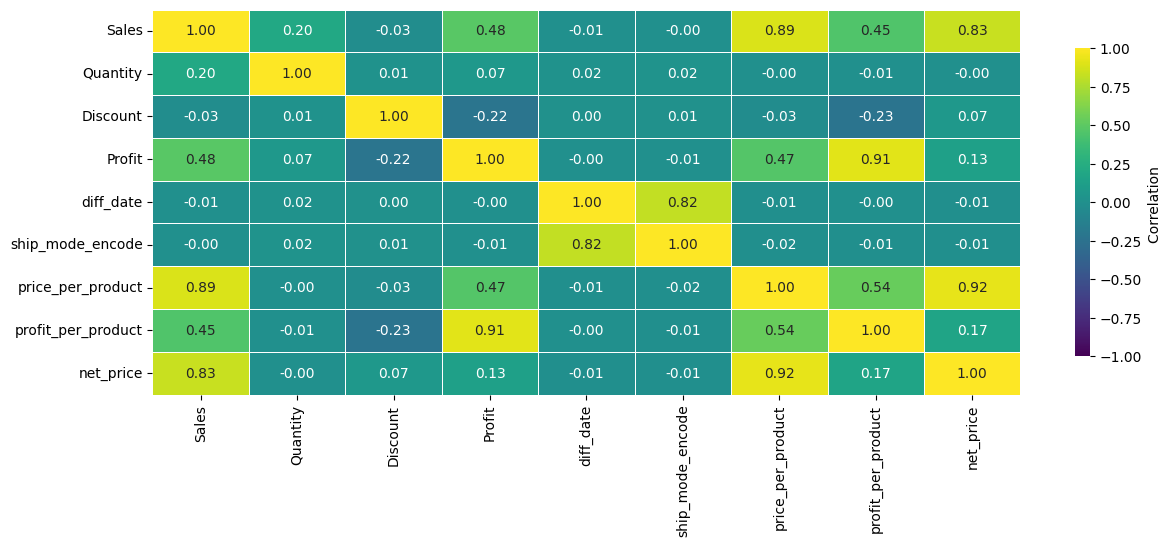

In [ ]:
fig, ax = plt.subplots(figsize=(14,5))
sns.heatmap(
    data_corr,
    ax= ax,
    cmap='viridis',
    vmin=-1,
    vmax=1,
    annot=True,
    fmt ='.2f',
    annot_kws={'size':10},
    linewidths=0.5,
    linecolor ='white',
    cbar_kws={ 'label':'Correlation ', 'shrink':0.8})